In [ ]:
   
# FinGuard - Notebook 03: Model Training + Threshold Tuning
# Research Paper Version - WITH PROPER VALIDATION
   

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os
import torch
import time

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, matthews_corrcoef,
    average_precision_score, precision_recall_curve, roc_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('./models_saved', exist_ok=True)
os.makedirs('./reports/figures', exist_ok=True)
os.makedirs('./reports/tables', exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
   
# 1. Load Data
   
print("Loading data...")
X_train = pd.read_csv('./data/processed/X_train_resampled.csv')
X_val   = pd.read_csv('./data/processed/X_val.csv')
X_test  = pd.read_csv('./data/processed/X_test.csv')

X_train_scaled = pd.read_csv('./data/processed/X_train_scaled.csv')
X_val_scaled   = pd.read_csv('./data/processed/X_val_scaled.csv')
X_test_scaled  = pd.read_csv('./data/processed/X_test_scaled.csv')

y_train = pd.read_csv('./data/processed/y_train_resampled.csv').squeeze()
y_val   = pd.read_csv('./data/processed/y_val.csv').squeeze()
y_test  = pd.read_csv('./data/processed/y_test.csv').squeeze()

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"Train fraud: {y_train.sum():,} | Val fraud: {y_val.sum():,} | Test fraud: {y_test.sum():,}")

Loading data...
Train: (4672700, 25) | Val: (954393, 25) | Test: (954393, 25)
Train fraud: 222,509 | Val fraud: 562 | Test fraud: 4,008


In [3]:
   
# 2. Initialize Models
   
print("\nInitializing models...")

#   1. Logistic Regression  
lr_model = LogisticRegression(
    C=0.5,
    class_weight=None,       # SMOTE handles balance
    random_state=RANDOM_STATE,
    max_iter=2000,
    solver='lbfgs',          # Faster than saga for this size
    n_jobs=-1
)

#   2. SVM (Memory-efficient with subsample)  
# NOTE: LinearSVC with 6M+ rows causes memory issues
# Use SGDClassifier (SVM-like, memory-efficient) OR subsample
svm_base = LinearSVC(
    C=0.1,
    class_weight=None,
    random_state=RANDOM_STATE,
    max_iter=3000,
    dual=False,
    tol=1e-3
)
svm_model = CalibratedClassifierCV(svm_base, cv=3, method='sigmoid')  # cv=3 faster

#   3. Decision Tree  
dt_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=50,
    min_samples_leaf=20,
    class_weight=None,
    random_state=RANDOM_STATE
)

#   4. Random Forest  
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=8,
    max_features='sqrt',
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=0
)

#   5. Gradient Boosting  
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.15,
    max_depth=5,
    subsample=0.8,
    min_samples_split=20,
    min_samples_leaf=8,
    random_state=RANDOM_STATE,
    verbose=0
)

#   6. XGBoost (GPU-accelerated)  
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=1,
    tree_method='hist',
    device='cuda' if torch.cuda.is_available() else 'cpu',
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

#   7. LightGBM  
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=80,
    max_depth=10,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

print("✓ All 7 models initialized")


Initializing models...
✓ All 7 models initialized


In [4]:
   
# 3. Train All Models
   
models_dict = {
    'Logistic Regression': (lr_model, 'scaled'),
    'SVM':                 (svm_model, 'scaled'),
    'Decision Tree':       (dt_model, 'raw'),
    'Random Forest':       (rf_model, 'raw'),
    'Gradient Boosting':   (gb_model, 'raw'),
    'XGBoost':             (xgb_model, 'raw'),
    'LightGBM':            (lgbm_model, 'raw'),
}

trained_models = {}
training_times = {}

for name, (model, data_type) in models_dict.items():
    print(f"\n{'─'*70}")
    print(f"⏳ Training {name}...")
    print(f"{'─'*70}")

    X_tr = X_train_scaled if data_type == 'scaled' else X_train

    # Memory check
    mem_gb = X_tr.memory_usage(deep=True).sum() / (1024**3)
    print(f"Data size: {X_tr.shape} ({mem_gb:.2f} GB)")

    try:
        t0 = time.time()
        model.fit(X_tr, y_train)
        elapsed = time.time() - t0

        trained_models[name] = (model, data_type)
        training_times[name] = elapsed
        print(f"✓ {name} trained in {elapsed:.1f}s ({elapsed/60:.2f} min)")

    except Exception as e:
        print(f"✗ {name} FAILED: {type(e).__name__}: {str(e)[:200]}")
        continue



──────────────────────────────────────────────────────────────────────
⏳ Training Logistic Regression...
──────────────────────────────────────────────────────────────────────
Data size: (4672700, 25) (0.87 GB)
✓ Logistic Regression trained in 17.1s (0.29 min)

──────────────────────────────────────────────────────────────────────
⏳ Training SVM...
──────────────────────────────────────────────────────────────────────
Data size: (4672700, 25) (0.87 GB)
✓ SVM trained in 35.0s (0.58 min)

──────────────────────────────────────────────────────────────────────
⏳ Training Decision Tree...
──────────────────────────────────────────────────────────────────────
Data size: (4672700, 25) (0.87 GB)
✓ Decision Tree trained in 74.0s (1.23 min)

──────────────────────────────────────────────────────────────────────
⏳ Training Random Forest...
──────────────────────────────────────────────────────────────────────
Data size: (4672700, 25) (0.87 GB)
✓ Random Forest trained in 329.7s (5.50 min)

──────

In [6]:
   
# 4. Threshold Optimization on VALIDATION Set
   
def find_best_threshold_f1(model, X_val, y_val):
    """Find threshold that maximizes F1 on validation set."""
    y_proba = model.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, y_proba)
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])


def find_best_threshold_cost(model, X_val, y_val, cost_fn=250, cost_fp=1):
    """Find threshold that minimizes cost on validation set."""
    y_proba = model.predict_proba(X_val)[:, 1]
    thresholds = np.linspace(0.01, 0.99, 200)
    best_thresh = 0.5
    min_cost = float('inf')
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
        cost = fn * cost_fn + fp * cost_fp
        if cost < min_cost:
            min_cost = cost
            best_thresh = t
    return float(best_thresh), min_cost

In [7]:
   
# 5. Evaluate on TEST Set (using Validation-optimized threshold)
   

print("MODEL EVALUATION (Threshold from Validation, Metrics from Test)")

results = {}

for name, (model, data_type) in trained_models.items():
    X_v  = X_val_scaled if data_type == 'scaled' else X_val
    X_te = X_test_scaled if data_type == 'scaled' else X_test

    # Threshold tuning on VALIDATION
    threshold = find_best_threshold_f1(model, X_v, y_val)

    # Evaluate on TEST
    y_proba = model.predict_proba(X_te)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    results[name] = {
        'threshold': threshold,
        'accuracy':  float(accuracy_score(y_test, y_pred)),
        'precision': float(precision_score(y_test, y_pred, zero_division=0)),
        'recall':    float(recall_score(y_test, y_pred, zero_division=0)),
        'f1':        float(f1_score(y_test, y_pred, zero_division=0)),
        'roc_auc':   float(roc_auc_score(y_test, y_proba)),
        'pr_auc':    float(average_precision_score(y_test, y_proba)),
        'mcc':       float(matthews_corrcoef(y_test, y_pred)),
        'fpr':       float(fp / (fp + tn)) if (fp + tn) > 0 else 0.0,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'train_time': training_times.get(name, 0.0),
    }

    print(f"\n{name}:")
    print(f"  Threshold (val-opt): {threshold:.4f}")
    print(f"  Precision:           {results[name]['precision']:.4f}")
    print(f"  Recall:              {results[name]['recall']:.4f}")
    print(f"  F1:                  {results[name]['f1']:.4f}")
    print(f"  ROC-AUC:             {results[name]['roc_auc']:.4f}")
    print(f"  PR-AUC:              {results[name]['pr_auc']:.4f}")
    print(f"  MCC:                 {results[name]['mcc']:.4f}")
    print(f"  FPR:                 {results[name]['fpr']:.6f}")
    print(f"  Train time:          {results[name]['train_time']:.1f}s")

MODEL EVALUATION (Threshold from Validation, Metrics from Test)

Logistic Regression:
  Threshold (val-opt): 0.8543
  Precision:           0.0268
  Recall:              0.9648
  F1:                  0.0521
  ROC-AUC:             0.9659
  PR-AUC:              0.4116
  MCC:                 0.1474
  FPR:                 0.147862
  Train time:          17.1s

SVM:
  Threshold (val-opt): 0.6711
  Precision:           0.0098
  Recall:              0.9965
  F1:                  0.0194
  ROC-AUC:             0.8600
  PR-AUC:              0.3186
  MCC:                 0.0747
  FPR:                 0.425199
  Train time:          35.0s

Decision Tree:
  Threshold (val-opt): 0.0024
  Precision:           0.0062
  Recall:              0.9795
  F1:                  0.0123
  ROC-AUC:             0.5406
  PR-AUC:              0.0043
  MCC:                 0.0434
  FPR:                 0.662466
  Train time:          74.0s

Random Forest:
  Threshold (val-opt): 0.8775
  Precision:           0.9516
  R

In [8]:
   
# 6. Summary Table (Research Paper Ready)
   
results_df = pd.DataFrame(results).T

print("FINAL RESULTS SUMMARY")
summary_cols = ['precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'mcc', 'fpr']
print(results_df[summary_cols].round(4))

# Save for paper
results_df.to_csv('./reports/tables/table4_model_results.csv')

best_model_name = results_df['f1'].idxmax()
best_metrics = results_df.loc[best_model_name]
print(f"\n🏆 Best Model (by F1): {best_model_name}")
print(best_metrics[summary_cols].round(4))


FINAL RESULTS SUMMARY
                     precision  recall      f1  roc_auc  pr_auc     mcc  \
Logistic Regression     0.0268  0.9648  0.0521   0.9659  0.4116  0.1474   
SVM                     0.0098  0.9965  0.0194   0.8600  0.3186  0.0747   
Decision Tree           0.0062  0.9795  0.0123   0.5406  0.0043  0.0434   
Random Forest           0.9516  0.4369  0.5988   0.8745  0.5632  0.6439   
Gradient Boosting       0.0243  0.1060  0.0395   0.7466  0.0133  0.0424   
XGBoost                 0.8205  0.4596  0.5892   0.9110  0.4949  0.6129   
LightGBM                0.9260  0.4247  0.5823   0.9631  0.5721  0.6262   

                        fpr  
Logistic Regression  0.1479  
SVM                  0.4252  
Decision Tree        0.6625  
Random Forest        0.0001  
Gradient Boosting    0.0180  
XGBoost              0.0004  
LightGBM             0.0001  

🏆 Best Model (by F1): Random Forest
precision    0.9516
recall       0.4369
f1           0.5988
roc_auc      0.8745
pr_auc       0.5632



✅ Models saved!


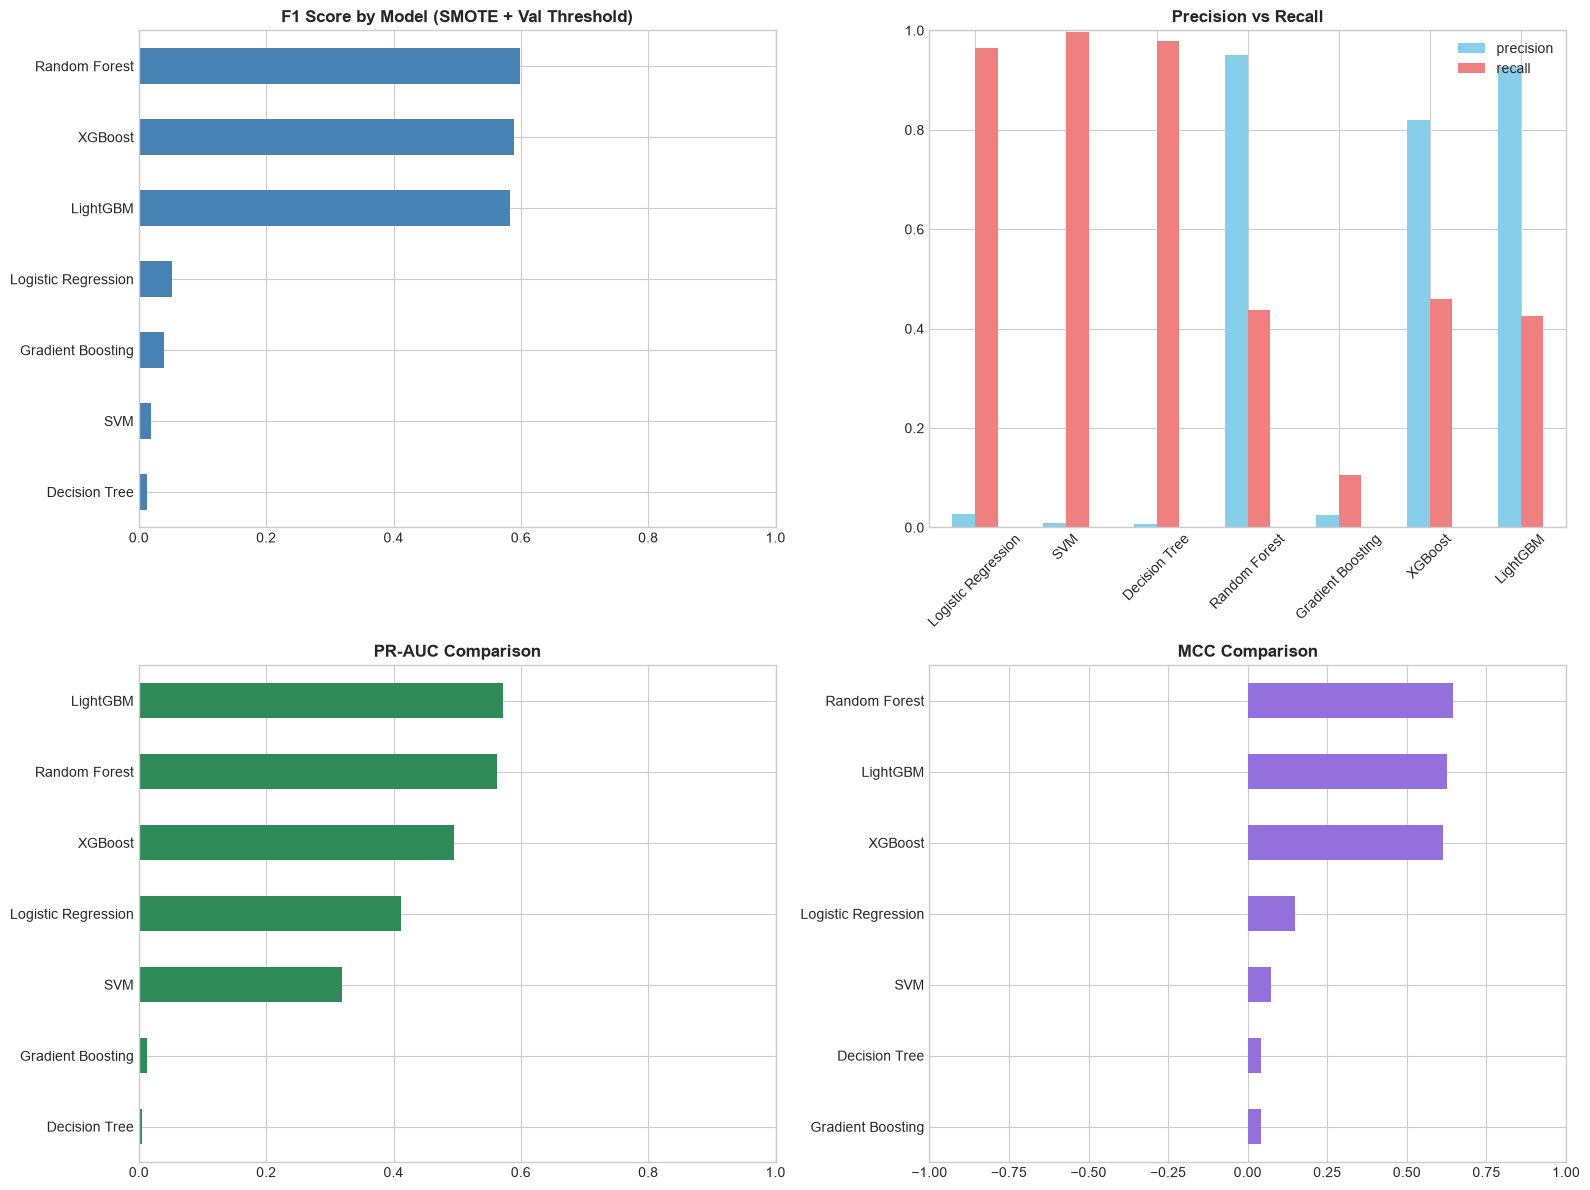

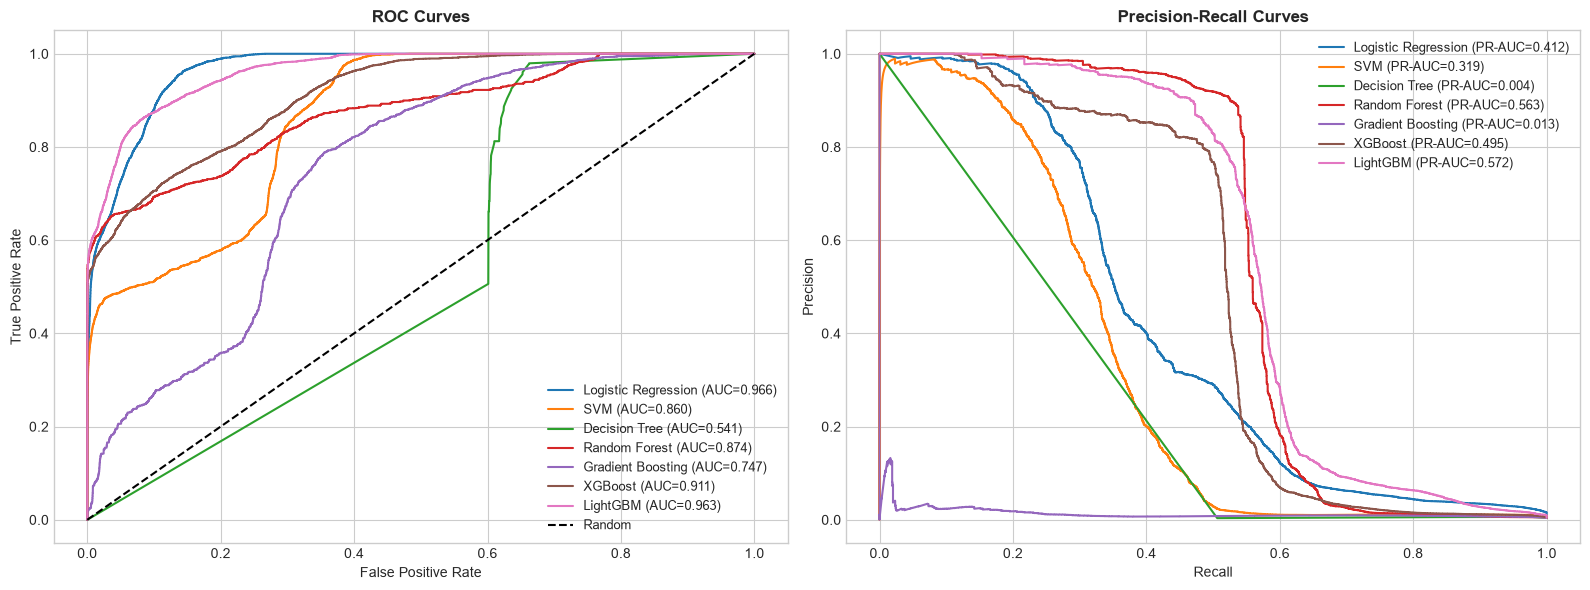

In [9]:
   
# 7. Save Models & Metadata
   
for name, (model, _) in trained_models.items():
    safe = name.lower().replace(' ', '_')
    joblib.dump(model, f'./models_saved/{safe}.pkl')

with open('./models_saved/model_metrics.json', 'w') as f:
    json.dump(results, f, indent=4)

with open('./models_saved/model_metadata.json', 'w') as f:
    json.dump({
        'best_model': best_model_name,
        'best_f1': float(best_metrics['f1']),
        'best_precision': float(best_metrics['precision']),
        'best_recall': float(best_metrics['recall']),
        'best_pr_auc': float(best_metrics['pr_auc']),
        'best_mcc': float(best_metrics['mcc']),
        'best_threshold': float(best_metrics['threshold']),
        'all_results': results
    }, f, indent=4)

print("\n✅ Models saved!")

   
# 8. Visualizations
   
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# F1 Score
results_df['f1'].sort_values().plot(kind='barh', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('F1 Score by Model (SMOTE + Val Threshold)', fontweight='bold')
axes[0,0].set_xlim(0, 1)

# Precision vs Recall
results_df[['precision', 'recall']].plot(kind='bar', ax=axes[0,1],
                                          color=['skyblue', 'lightcoral'])
axes[0,1].set_title('Precision vs Recall', fontweight='bold')
axes[0,1].set_ylim(0, 1)
axes[0,1].legend()
axes[0,1].tick_params(axis='x', rotation=45)

# PR-AUC
results_df['pr_auc'].sort_values().plot(kind='barh', ax=axes[1,0], color='seagreen')
axes[1,0].set_title('PR-AUC Comparison', fontweight='bold')
axes[1,0].set_xlim(0, 1)

# MCC
results_df['mcc'].sort_values().plot(kind='barh', ax=axes[1,1], color='mediumpurple')
axes[1,1].set_title('MCC Comparison', fontweight='bold')
axes[1,1].set_xlim(-1, 1)

plt.tight_layout()
plt.savefig('./reports/figures/fig7_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, (model, data_type) in trained_models.items():
    X_te = X_test_scaled if data_type == 'scaled' else X_test
    y_proba = model.predict_proba(X_te)[:, 1]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")

    # PR
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={results[name]['pr_auc']:.3f})")

axes[0].plot([0,1], [0,1], 'k--', label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('./reports/figures/fig8_roc_pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()